<a href="https://colab.research.google.com/github/mishra2arya/Unsuppervised-learning/blob/main/PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Original dataset shape: (5000, 784)
compressed dataset shape: (5000, 148)
reconstructed dataset shape: (5000, 784)


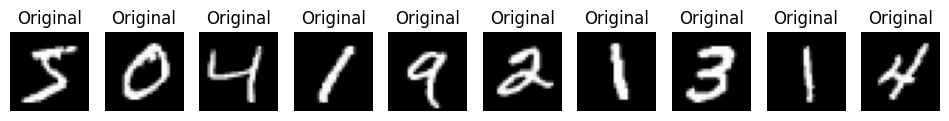

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA


mnist=fetch_openml(
    "mnist_784",
    version=1,
    as_frame=False
)

X=mnist.data
X=X[:5000]
print("Original dataset shape:", X.shape)
X=X/255.0
pca=PCA(n_components=0.95)
X_compressed=pca.fit_transform(X)
print("compressed dataset shape:", X_compressed.shape)
X_reconstructed=pca.inverse_transform(X_compressed)
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 10, i+1)
    plt.imshow(X[i].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")
print("reconstructed dataset shape:", X_reconstructed.shape)

In [2]:
print("Original features:", X.shape[1])
print("Explained variance:", round(pca.explained_variance_ratio_.sum(), 4))
reduction = (1 - X_compressed.shape[1] / X.shape[1]) * 100
print("Dimensionality reduction:", round(reduction, 2), "%")

Original features: 784
Explained variance: 0.9501
Dimensionality reduction: 81.12 %


In [11]:
import pandas as pd

df_country = pd.read_csv('/content/Country-data.csv')
display(df_country.head())

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


In [12]:
from sklearn.preprocessing import StandardScaler

# Exclude 'country' column which is categorical
X_country = df_country.drop(columns=['country'])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_country)
print("Scaled features shape:", X_scaled.shape)

Scaled features shape: (167, 9)


In [13]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca_country = PCA(n_components=0.90)
X_pca = pca_country.fit_transform(X_scaled)

print("PCA reduced shape:", X_pca.shape)
print("Explained variance ratio per component:", pca_country.explained_variance_ratio_)
print("Total explained variance:", round(pca_country.explained_variance_ratio_.sum() * 100, 2), "%")

PCA reduced shape: (167, 5)
Explained variance ratio per component: [0.4595174  0.17181626 0.13004259 0.11053162 0.07340211]
Total explained variance: 94.53 %


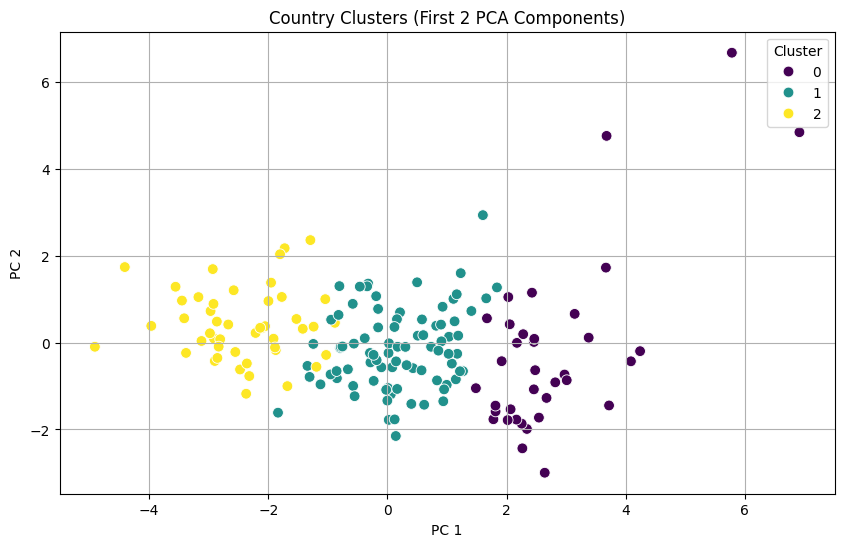

In [15]:
from sklearn.cluster import KMeans
import seaborn as sns

# Apply K-Means clustering (let's assume 3 clusters for illustration)
k_means = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = k_means.fit_predict(X_pca)

df_country['Cluster'] = clusters

# Plot the first two PCA components and color by cluster
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df_country['Cluster'], palette='viridis', s=60)
plt.title('Country Clusters (First 2 PCA Components)')
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.grid(True)
plt.show()